# Class 5 Challenge — Fetching Data with SQL, APIs and Files (FlashEats)

> **Client:** “Late deliveries are increasing and customers say our ETA is unreliable. Figure out what is happening before we invest in an AI delay-prediction system.”

**Method:** define the question → retrieve evidence → validate completeness → reconcile sources → state what we know and what we cannot know.

This notebook is the *exploration* that was later hardened into `run_pipeline.py` (Class 8). It reads the client systems in `source_systems/` directly.

In [1]:
import json, sqlite3, subprocess, sys, time
from pathlib import Path
import pandas as pd, requests, matplotlib.pyplot as plt

BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SRC = BASE / "source_systems"
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)
con = sqlite3.connect(SRC / "database" / "flasheats.db")
print(pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", con))

          name
0    customers
1      drivers
2  restaurants
3       orders


## Source map first (before any analysis)

| Information | Source (system) | Retrieval | Authoritative or contextual? |
|---|---|---|---|
| Promised delivery time | `orders.promised_eta` — Order Platform DB | SQL | **Authoritative** for the customer promise |
| Actual delivery time | `orders.actual_delivery_at` — Order DB; `delivered` event — Driver App | SQL / JSON | Order DB authoritative; Driver App = observed event, validated fallback |
| Driver assignment | Dispatch Service (`assigned_at`, `reassigned_at`, current `driver_id`) | REST API | **Authoritative** — Dispatch owns assignment (Order DB keeps the original driver) |
| Customer complaint | `support_tickets.csv` — Support platform | CSV | Contextual — customer *perception*, not an event log |
| Restaurant status | `restaurant_status.csv` — restaurant feed | CSV | Contextual only — manual, last-updated snapshot |
| Driver movement/events | `driver_events.json` — Driver App | nested JSON | Authoritative for pickup; GPS is sparse |

# Challenge 1 — How large is the late-delivery problem?

- **Late means:** `actual_delivery_at > promised_eta` (any positive delay — VP Operations' definition).
- **Denominator:** unique orders with final status *delivered* (any case), a non-null delivery time and a non-null promise.
- **Cancelled orders:** excluded — they never had a delivery to be late.
- **Missing actual delivery timestamp:** excluded *here* (Class 5 rule) but counted and reported; see the end of this challenge.
- **Row grain:** one row = one order (`order_id`). The table breaks that grain → de-duplicate first.

In [2]:
grain = pd.read_sql("""
SELECT COUNT(*) AS raw_rows, COUNT(DISTINCT order_id) AS unique_orders,
       SUM(LOWER(final_status)='cancelled') AS cancelled,
       SUM(LOWER(final_status)='delivered' AND actual_delivery_at IS NULL) AS delivered_missing_actual
FROM orders""", con)
grain

,raw_rows,unique_orders,cancelled,delivered_missing_actual
0,1603,1600,68,37


In [3]:
# SQL does the heavy lifting: de-duplicate at the order grain, then filter to the valid population
valid = pd.read_sql("""
WITH one_row_per_order AS (
    SELECT * FROM orders WHERE rowid IN (SELECT MIN(rowid) FROM orders GROUP BY order_id)
)
SELECT order_id, created_at, promised_eta, actual_delivery_at, traffic_bucket, weather_bucket, distance_km_estimate
FROM one_row_per_order
WHERE LOWER(final_status) = 'delivered' AND actual_delivery_at IS NOT NULL AND promised_eta IS NOT NULL
""", con)
for c in ["created_at", "promised_eta", "actual_delivery_at"]:
    valid[c] = pd.to_datetime(valid[c], format="mixed")        # timestamps mix second and microsecond precision
valid["delay_min"] = (valid.actual_delivery_at - valid.promised_eta).dt.total_seconds() / 60
late = valid[valid.delay_min > 0]
print(f"valid delivered orders: {len(valid)}")
print(f"late: {len(late)}  -> late rate {100*len(late)/len(valid):.1f}%")
print(f"median lateness among late orders: {late.delay_min.median():.1f} min;  > 10 min late: {100*(valid.delay_min>10).mean():.1f}%")
late.sort_values("delay_min", ascending=False).head(5)[["order_id", "promised_eta", "actual_delivery_at", "delay_min", "traffic_bucket", "weather_bucket"]]

valid delivered orders: 1495
late: 843  -> late rate 56.4%
median lateness among late orders: 8.0 min;  > 10 min late: 23.3%


,order_id,promised_eta,actual_delivery_at,delay_min,traffic_bucket,weather_bucket
98,O00104,2026-08-09 22:09:00.000000,2026-08-09 23:36:20.740161,87.345669,medium,clear
96,O00102,2026-08-11 16:31:00.000000,2026-08-11 17:57:17.661772,86.294363,medium,clear
95,O00101,2026-08-24 20:49:00.000000,2026-08-24 22:14:30.685278,85.511421,low,rain
97,O00103,2026-08-22 20:01:00.000000,2026-08-22 21:10:17.342305,69.289038,high,clear
1011,O01081,2026-08-13 18:15:46.613098,2026-08-13 19:06:02.677891,50.267747,high,clear


In [4]:
# Data-quality issue that changes the metric: are the 37 'missing' deliveries really missing?
de = json.loads((SRC / "exports" / "driver_events.json").read_text())
ev = pd.DataFrame([{"driver_id": d["driver_id"], **e} for d in de for e in d["events"]])
app_delivered = ev[ev.type == "delivered"].set_index("order_id").timestamp.pipe(pd.to_datetime, format="mixed")
o = pd.read_sql("SELECT * FROM orders", con).drop_duplicates("order_id")
o["actual"] = pd.to_datetime(o.actual_delivery_at, format="mixed")
missing = o[(o.final_status.str.lower() == "delivered") & o.actual.isna()]
both = o.dropna(subset=["actual"]).join(app_delivered.rename("app"), on="order_id").dropna(subset=["app"])
print("missing in Order DB:", len(missing), "| of those with a Driver App 'delivered' event:", missing.order_id.isin(app_delivered.index).sum())
print("agreement where both exist:", ((both.app - both.actual).abs().dt.total_seconds() <= 60).mean() * 100, "% of", len(both))

missing in Order DB: 37 | of those with a Driver App 'delivered' event: 37
agreement where both exist: 100.0 % of 1495


**Answer.** Under the VP Ops definition, **56.4% of 1,495 valid delivered orders are late** (median lateness 8.0 min among late orders; 23.3% are more than 10 min late).

**Look at the 'worst delayed' list:** the top 4 (O00101–O00104, ~70–87 min) are exactly the orders whose promise was made 10 minutes *before* the order existed — the worst delays are a data artifact, not operations.

**Data-quality issues that change the metric:** 3 duplicate order rows (and they *disagree* on `traffic_bucket`, so they are not harmless copies), 68 cancellations, 37 delivered orders without a completion time. Those 37 are **recoverable** — the Driver App recorded their `delivered` event and agrees with the Order DB on 100% of the 1,495 overlapping orders. The pipeline recovers them (flagged), moving the KPI population to 1,532 → then 4 orders promised *before* they were created are excluded, giving the published **56.5% of 1,528**.

# Challenge 2 — Operations says: “Traffic is the problem.”
Test with ≥ 3 dimensions. Separate **association** from **causation**.

In [5]:
valid["hour"] = valid.created_at.dt.hour
valid["daypart"] = pd.cut(valid.hour, [0, 14, 17, 21, 24], labels=["lunch 11-14", "afternoon 14-17", "dinner 17-21", "late 21-24"], right=False)
valid["distance_is_default"] = valid.distance_km_estimate == 18.0
summ = lambda col: valid.groupby(col, observed=True).delay_min.agg(orders="count", late_rate=lambda s: round(100*(s>0).mean(),1), median_delay="median").round(1)
display(summ(valid.traffic_bucket.str.lower()))
display(summ("weather_bucket"))
display(summ("daypart"))
print("share of orders with distance exactly 18.0 km:", round(100*valid.distance_is_default.mean(),1), "%  <- a default value, not a measurement")
real = valid[~valid.distance_is_default]
display(real.groupby(pd.cut(real.distance_km_estimate, [0,5,10,15,50]), observed=True).delay_min.agg(orders="count", late_rate=lambda s: round(100*(s>0).mean(),1)))

,orders,late_rate,median_delay
traffic_bucket,,,
high,424,66.5,4.0
low,360,49.4,-0.1
medium,588,51.4,0.3
severe,123,65.9,4.3


,orders,late_rate,median_delay
weather_bucket,,,
clear,1192,53.3,0.8
heavy_rain,72,73.6,6.6
rain,231,67.1,4.3


,orders,late_rate,median_delay
daypart,,,
lunch 11-14,311,55.9,1.2
afternoon 14-17,206,60.2,2.1
dinner 17-21,729,56.9,1.7
late 21-24,249,52.2,1.0


share of orders with distance exactly 18.0 km: 50.1 %  <- a default value, not a measurement


,orders,late_rate
distance_km_estimate,,
"(0, 5]",69,53.6
"(5, 10]",222,55.9
"(10, 15]",300,52.7
"(15, 50]",155,63.9


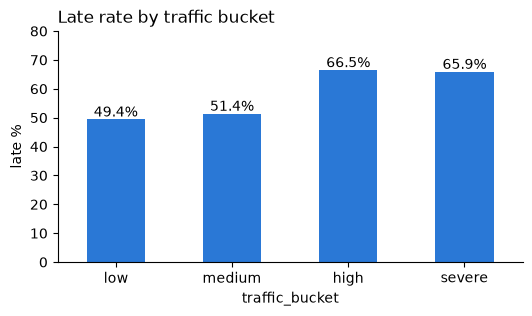

In [6]:
t = summ(valid.traffic_bucket.str.lower()).reindex(["low", "medium", "high", "severe"])
ax = t.late_rate.plot(kind="bar", color="#2a78d6", figsize=(6,3), rot=0)
for i, v in enumerate(t.late_rate): ax.text(i, v + 1, f"{v}%", ha="center")
ax.set_title("Late rate by traffic bucket", loc="left"); ax.set_ylabel("late %"); ax.set_ylim(0, 80)
for s in ["top", "right"]: ax.spines[s].set_visible(False)
plt.show()

**Hypothesis supported by evidence:** traffic and weather are **associated** with lateness — high/severe traffic ≈ 65% late vs ≈ 50% in low; rain/heavy rain 67–74% vs 53% clear.

**But:** half the orders carry a *default* distance of 18.0 km, so the class's “distance doesn't matter” table was built on placeholder values; on real distances there is only a mild uptick beyond 15 km (64% vs 53–56%) — the promise window already scales with distance, so distance is largely priced into the ETA.

**Alternative explanation we cannot rule out:** the gap between late and on-time orders opens **before pickup** (restaurant readiness / driver arrival — see Class 7), and traffic buckets may simply co-occur with peak dinner load. This is descriptive association, not causal proof.

# Challenge 3 — Customer Support disagrees

In [7]:
tickets = pd.read_csv(SRC / "exports" / "support_tickets.csv")
print("rows:", len(tickets), "| unique ticket_id:", tickets.ticket_id.nunique(), "| exact duplicate rows:", tickets.duplicated().sum(), "| no order_id:", tickets.order_id.isna().sum())
display(tickets.category.value_counts(dropna=False))
tk = tickets.drop_duplicates().dropna(subset=["order_id"]).copy()
tk["category_norm"] = tk.category.str.strip().str.lower().str.replace(" ", "_")
tk = tk.merge(valid[["order_id", "promised_eta", "delay_min"]], on="order_id", how="left")
tk["created_at"] = pd.to_datetime(tk.created_at)
view = tk.groupby("category_norm").agg(tickets=("ticket_id", "count"), system_says_late=("delay_min", lambda s: round(100*(s>0).mean(),1)), median_delay=("delay_min", "median"),
                                          raised_before_promise=("created_at", lambda s: int((s < tk.loc[s.index, "promised_eta"]).sum())))
view.round(1)

rows: 202 | unique ticket_id: 201 | exact duplicate rows: 1 | no order_id: 3


category
late_delivery        38
eta_changed          37
restaurant_delay     37
ready_but_waiting    33
status_mismatch      29
driver_not_moving    25
Late Delivery         1
late_delivery         1
ETA issue             1
Name: count, dtype: int64

,tickets,system_says_late,median_delay,raised_before_promise
category_norm,,,,
driver_not_moving,25,68.0,10.4,24
eta_changed,36,77.8,7.7,34
eta_issue,1,100.0,5.4,1
late_delivery,38,86.8,14.8,38
ready_but_waiting,33,90.9,12.2,32
restaurant_delay,37,75.7,10.5,35
status_mismatch,28,92.9,12.7,27


In [8]:
print("late orders that produced a ticket:", round(100*late.order_id.isin(tk.order_id).mean(),1), "%")

late orders that produced a ticket: 19.3 %


| | Customer view (tickets) | System view (orders + events) |
|---|---|---|
| Size | 201 tickets | 843 late orders — only **~19% of late orders produce a ticket** → tickets under-count the problem |
| What | late delivery, ETA keeps changing, restaurant delay, “ready but no rider” | lateness is mostly created before pickup |
| Agreement | 68–93% of ticketed orders (by category) really were late | ✔ the complaints are mostly genuine |
| Conflict | “already past the promised time” tickets are raised **before** the stored `promised_eta` | the ETA the customer *saw* is not the one stored → unknown |

**What tickets tell us that timestamps cannot:** *where the customer thinks* the failure is (restaurant vs rider vs app) and that the *displayed* ETA moves — neither is recorded as an event. Ticket IDs are not unique (1 exact duplicate) and 3 tickets have no order.

# Challenge 4 — Dispatch API: prove you retrieved everything

In [9]:
API = "http://127.0.0.1:8000"
proc = subprocess.Popen([sys.executable, str(SRC / "dispatch_api" / "mock_dispatch_api.py")], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
for _ in range(30):
    try:
        if requests.get(f"{API}/health", timeout=1).ok: break
    except requests.RequestException: time.sleep(0.3)
print(requests.get(f"{API}/health").json())
RAW = BASE / "data" / "notebook_scratch" / "raw_dispatch"; RAW.mkdir(parents=True, exist_ok=True)

def fetch_all(page_size=100, max_retries=4):
    rows, page, expected, log = [], 1, None, []
    while True:
        for attempt in range(1, max_retries + 1):
            r = requests.get(f"{API}/dispatch/orders", params={"page": page, "page_size": page_size}, timeout=5)
            if r.status_code in (429, 500, 502, 503, 504):             # transient -> bounded retry with backoff
                log.append((page, r.status_code, attempt)); time.sleep(min(2 ** (attempt - 1), 4)); continue
            r.raise_for_status(); break                                   # anything else -> fail loudly
        else:
            raise RuntimeError(f"page {page} failed after {max_retries} attempts")
        payload = r.json()
        (RAW / f"dispatch_page_{page:03d}.json").write_text(json.dumps(payload))   # preserve raw BEFORE using it
        expected = expected or payload["total_records"]; rows += payload["data"]
        if not payload["has_more"]: break
        page += 1
    if len(rows) != expected: raise RuntimeError(f"incomplete: {len(rows)} vs {expected}")
    return pd.DataFrame(rows), log, page

dispatch, retry_log, pages = fetch_all()
proc.terminate()
print("retries:", retry_log)
print(f"pages={pages} rows={len(dispatch)} unique order_ids={dispatch.order_id.nunique()} reported total={1600} raw pages saved={len(list(RAW.glob('*.json')))}")
print("reassigned orders:", dispatch.reassigned_at.notna().sum())

{'service': 'flasheats-dispatch-api', 'status': 'ok'}


retries: [(3, 500, 1), (5, 429, 1)]
pages=16 rows=1600 unique order_ids=1600 reported total=1600 raw pages saved=16
reassigned orders: 95


**Completeness proof:** 16/16 pages saved raw, 1,600 rows = the API's `total_records` = 1,600 unique `order_id`s = orders in the Order DB. Page 3 (HTTP 500) and page 5 (HTTP 429) failed once and succeeded on retry — a single HTTP 200 would *not* have proven the job succeeded. 95 orders were reassigned, so `orders.driver_id` (original driver) is **not** the current driver.

# Challenge 5 — Can we attribute the delay?

In [10]:
ev["ts"] = pd.to_datetime(ev.timestamp, format="mixed")
print(ev.type.value_counts())
print("explicit arrived_at_restaurant events:", (ev.type == "arrived_at_restaurant").sum())
life = ev[ev.type != "gps_ping"].pivot_table(index="order_id", columns="type", values="ts", aggfunc="first")
gps = ev[ev.type == "gps_ping"].join(life, on="order_id")
print("GPS pings in transit (between pickup and delivery), BY TIMESTAMP:", ((gps.ts >= gps.picked_up) & (gps.ts <= gps.delivered)).sum())
gap = ev[ev.type == "gps_ping"].sort_values(["order_id", "ts"]).groupby("order_id").ts.diff().dt.total_seconds().div(60)
print("median minutes between GPS pings:", round(gap.median(), 1))
print("driver arrays that are NOT in time order:", sum(not pd.to_datetime(pd.Series([e['timestamp'] for e in d['events']]), format='mixed').is_monotonic_increasing for d in de), "of", len(de))

type
gps_ping     5371
assigned     1600
picked_up    1532
delivered    1532
Name: count, dtype: int64
explicit arrived_at_restaurant events: 0
GPS pings in transit (between pickup and delivery), BY TIMESTAMP: 3739
median minutes between GPS pings: 13.4
driver arrays that are NOT in time order: 120 of 120


| Event / fact | Observed? | Source | Reliability concern |
|---|---|---|---|
| Driver assigned | **Observed** | Dispatch API `assigned_at` (= Driver App `assigned`) | reassignment overwrites the driver — Order DB keeps the original |
| Driver at restaurant | **Not observed** — only *inferable* | GPS pings | pings every ~13 min → far too sparse for a geofence; no `arrived` event |
| Picked up | **Observed** | Driver App `picked_up` | Order DB `pickup_at` is wrong for 5 orders and filled for cancelled orders |
| Delivered | **Observed** | Order DB + Driver App (agree 100%) | 37 missing in the DB, recoverable from the app |

Note: the JSON lists each driver's GPS pings *before* the pickup event even when they happened after it — reading array order suggests “no GPS after pickup”, sorting by timestamp shows 3,700+ in-transit pings. **Always sort events by time.**

# Final FDE synthesis — one slide

1. **Problem size** — The data shows 56.4% of 1,495 valid delivered orders (56.5% of 1,528 after recovering 37 and removing 4 impossible promises) arrive after the promised ETA; median lateness 8.0 min; ~23% are > 10 min late.
2. **Evidence** — Traffic and rain are *associated* with lateness, but the biggest gap between late and on-time orders opens before pickup (Class 7). Distance is unusable as-is (50% default values).
3. **Trusted sources** — Order DB for promise/outcome; Dispatch API for assignment; Driver App for pickup (and as a validated delivery fallback); tickets = customer perception.
4. **Uncertainty** — We cannot determine whether restaurants or drivers cause the pickup delay; we do not know which ETA the customer saw.
5. **Instrumentation recommendation** — capture `DRIVER_ARRIVED_AT_RESTAURANT` and `FOOD_READY` events, store the customer-displayed ETA, stop defaulting distance to 18 km.
6. **Decision** — **Do not build the AI delay predictor now.** We would need reliable stage events and agreed delay labels before a model could learn anything we could act on.